# Task 4: Image Clustering using K-Means

### 0. Introduction

- **Clustering** is an unsupervised learning technique that groups data points by similarity, **without using labels**.
- **K-Means** is the most widely used clustering algorithm. It splits the data into K groups, each represented by its centroid (the mean of its points).
- **Objective:** apply K-Means to **MNIST handwritten digits**, then check how well the discovered clusters match the true digits.
- The true labels are used **only for evaluation**, never for fitting.

| Section | Content |
|:---:|:---|
| 1 | Core concepts: clustering, centroids, Euclidean distance, within-cluster variance |
| 2 | Dataset: MNIST |
| 3 | K-Means algorithm and implementation (from scratch vs scikit-learn) |
| 4 | Image concepts and choosing K |
| 5 | Evaluating clusters against the true labels |
| 6 | Cluster visualization and interpretation |
| 7 | Conclusion |

In [1]:
# Imports

import time
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs, fetch_openml


# Reproducibility

np.random.seed(42)


## 1. Core Concepts of K-Means

### Clustering and unsupervised learning

| | Classification (supervised) | Clustering (unsupervised) |
|:---|:---|:---|
| **Labels** | Required for training | Not used |
| **Goal** | Predict a known category | Discover structure in the data |
| **Output** | A class from a fixed set | Group IDs (arbitrary numbers, with no inherent meaning) |

**Main types of clustering**

| Type | Idea | Example |
|:---|:---|:---|
| **Partition-based** | Split the data into K groups around representative points | K-Means |
| **Hierarchical** | Build a tree of nested clusters by merging or splitting | Agglomerative clustering |
| **Density-based** | Clusters are dense regions separated by sparse regions; can find odd shapes and outliers | DBSCAN |

### Cluster centroids

- The **centroid** of a cluster is the **mean** of all points in it: $\mu_k = \dfrac{1}{|C_k|}\sum_{x \in C_k} x$
- K-Means represents each cluster by its centroid.
- For MNIST, a centroid has 784 values, so it can be displayed as an "average digit" image.

### Euclidean distance

- The straight-line distance between a point $x$ and a centroid $\mu$ in $d$ dimensions: $d(x, \mu) = \sqrt{\sum_{i=1}^{d} (x_i - \mu_i)^2}$
- Each point is assigned to its **nearest** centroid.
- In very high dimensions, distances between points become less distinct (see the curse of dimensionality in Section 4).

### Within-cluster variance (inertia)

- Measures how tight the clusters are: the sum of squared distances from every point to its own centroid. It is called **inertia** or **WCSS** (within-cluster sum of squares).

$$J = \sum_{k=1}^{K} \sum_{x \in C_k} \lVert x - \mu_k \rVert^2$$

- **K-Means minimizes $J$.** Lower inertia means tighter clusters.
- Inertia always decreases as K increases (K = n gives 0), so it cannot be used alone to pick K (see Section 6).



### 2. Dataset: MNIST

| Property | Value |
|:---|:---|
| **Content** | Grayscale images of handwritten digits |
| **Images** | 70,000 in total (60,000 standard training and 10,000 standard test) |
| **Image size** | 28 × 28 pixels = **784 features** per image |
| **Pixel values** | Integers from 0 (black) to 255 (white) |
| **Classes** | 10 digits (0 to 9), roughly balanced |

- Clustering is **unsupervised**, so the standard train/test split is not needed. The 60,000 and 10,000 images are combined, K-Means is fitted on all 70,000, and the labels are kept aside for evaluation only.
- The data is read from the **local raw IDX files**, so no internet or `torchvision` is needed.
- Images are stored as flat rows of 784 values. They are reshaped to 28 × 28 only for display.

#### EDA in this section

- Shapes, pixel range and missing values
- Class distribution
- Sample images
- Mean image per digit, which is what an ideal centroid would look like if the clusters matched the digits perfectly

Images: (70000, 784) | Labels: (70000,)
Pixel range: 0.0 to 255.0
Missing values: 0
Classes: [0 1 2 3 4 5 6 7 8 9]

Images per digit: {0: np.int64(6903), 1: np.int64(7877), 2: np.int64(6990), 3: np.int64(7141), 4: np.int64(6824), 5: np.int64(6313), 6: np.int64(6876), 7: np.int64(7293), 8: np.int64(6825), 9: np.int64(6958)}


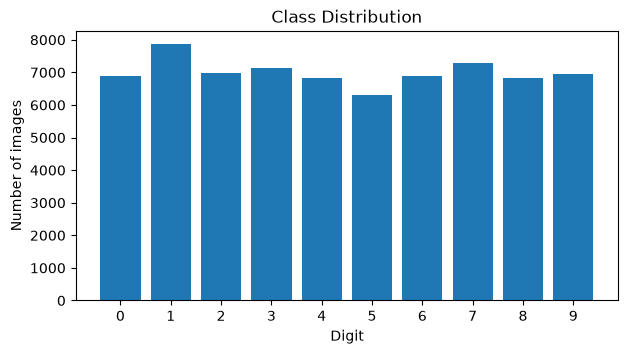

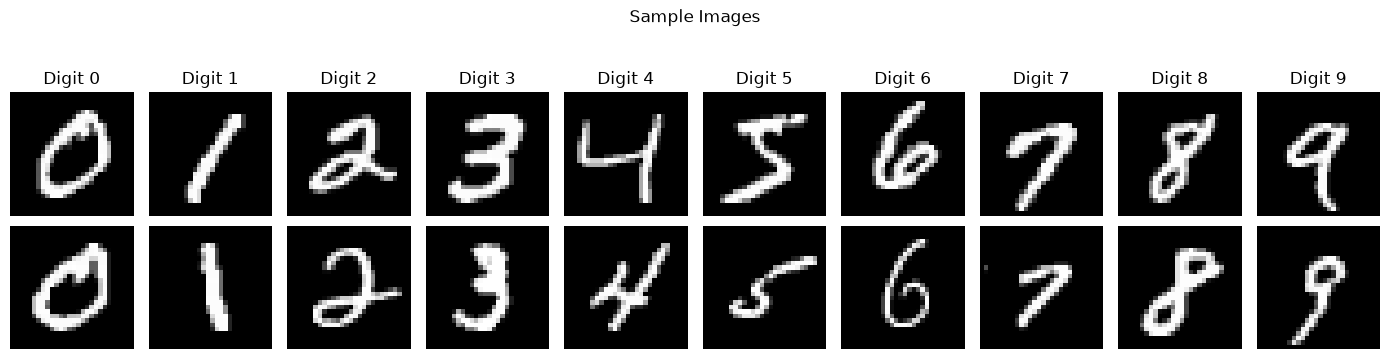

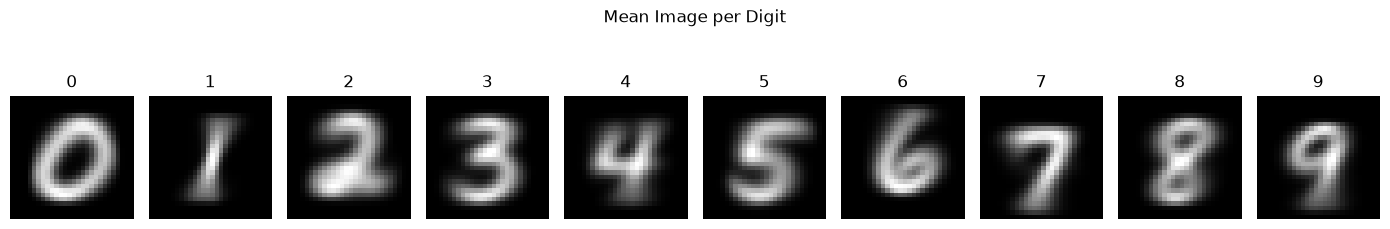

In [2]:
import os
import struct


# Folder containing the four MNIST IDX files

DATA_DIR = r"C:\Users\rithy\OneDrive\Desktop\marvel_level3\task_4\data"


# Readers for the raw IDX format

def read_idx_images(path):
    with open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows * cols)

def read_idx_labels(path):
    with open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)


# Load the standard train and test sets, then combine them into 70,000 images

X_train_raw = read_idx_images(os.path.join(DATA_DIR, "train-images.idx3-ubyte"))
y_train_raw = read_idx_labels(os.path.join(DATA_DIR, "train-labels.idx1-ubyte"))
X_test_raw = read_idx_images(os.path.join(DATA_DIR, "t10k-images.idx3-ubyte"))
y_test_raw = read_idx_labels(os.path.join(DATA_DIR, "t10k-labels.idx1-ubyte"))

X_all = np.vstack([X_train_raw, X_test_raw]).astype("float32")    # shape (70000, 784)
y_all = np.concatenate([y_train_raw, y_test_raw]).astype(int)     # shape (70000,)


# Basic information

print("Images:", X_all.shape, "| Labels:", y_all.shape)
print("Pixel range:", X_all.min(), "to", X_all.max())
print("Missing values:", np.isnan(X_all).sum())
print("Classes:", np.unique(y_all))


# Class distribution

counts = np.bincount(y_all)
print("\nImages per digit:", dict(enumerate(counts)))

plt.figure(figsize=(7, 3.5))
plt.bar(range(10), counts)
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Number of images")
plt.title("Class Distribution")
plt.show()


# Sample images (two examples of each digit)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))
for digit in range(10):
    idx = np.where(y_all == digit)[0][:2]
    for row, i in enumerate(idx):
        axes[row, digit].imshow(X_all[i].reshape(28, 28), cmap="gray")
        axes[row, digit].axis("off")
        if row == 0:
            axes[row, digit].set_title(f"Digit {digit}")
plt.suptitle("Sample Images", y=1.05)
plt.tight_layout()
plt.show()


# Mean image per digit (the ideal centroid if clusters matched digits)

fig, axes = plt.subplots(1, 10, figsize=(14, 2.2))
for digit in range(10):
    axes[digit].imshow(X_all[y_all == digit].mean(axis=0).reshape(28, 28), cmap="gray")
    axes[digit].set_title(str(digit))
    axes[digit].axis("off")
plt.suptitle("Mean Image per Digit", y=1.1)
plt.tight_layout()
plt.show()

### 3. K-Means Algorithm and Implementation

#### Steps (Lloyd's algorithm)

1. **Choose K**, the number of clusters.
2. **Initialize** K centroids.
3. **Assign:** each point goes to its nearest centroid (Euclidean distance).
4. **Update:** each centroid moves to the mean of the points assigned to it.
5. **Repeat** steps 3 and 4 until the assignments stop changing (or a maximum number of iterations is reached).

#### Why it converges

- The assign step and the update step each **reduce or keep** the inertia, and there are only finitely many ways to assign points.
- So K-Means always stops, but at a **local minimum**, not necessarily the global one. Different starting centroids can give different final clusterings.

#### Initialization

| Method | How it works | Issue / benefit |
|:---|:---|:---|
| **Random** | Pick K random data points as the starting centroids | Can place several centroids in the same group, leading to a poor local minimum |
| **K-Means++** | First centroid chosen at random; each next centroid is chosen with probability proportional to its **squared distance** from the nearest centroid already chosen | Spreads the starting centroids apart; usually gives better and more consistent results |

- **`n_init`:** run the whole algorithm several times from different starts and keep the run with the **lowest inertia**.

#### Complexity and limitations

- **Cost:** about $O(n \cdot K \cdot d)$ per iteration, for $n$ points, $K$ clusters and $d$ features.

| Limitation | Consequence |
|:---|:---|
| K must be chosen in advance | Needs methods such as the elbow or silhouette (Section 6) |
| Finds only a local minimum | Use K-Means++ and several initializations |
| Assumes roughly round, similar-sized clusters | Struggles with elongated or irregular shapes |
| Sensitive to outliers and feature scale | Normalize the features first |
| Relies on Euclidean distance | Less effective on raw high-dimensional data such as pixels |

#### Implementation on MNIST

| Setting | Value |
|:---|:---|
| **Data** | All 70,000 images, scaled to 0-1 (explained in Section 4) |
| **K** | 10 (checked in Section 6) |
| **Initialization** | K-Means++ in both models |
| **`n_init`** | 3 runs, keeping the lowest inertia |
| **Labels** | **Not used** in fitting. Used only for evaluation in Section 7 |

- **From scratch (NumPy):** squared distances are computed as $\lVert x - c \rVert^2 = \lVert x \rVert^2 - 2\,x \cdot c + \lVert c \rVert^2$, which is one matrix multiplication. This avoids building a huge `(70000, 10, 784)` array.
- **scikit-learn:** `KMeans(init="k-means++", n_init=3)` on the same data.
- **Comparison:** inertia, iterations, fit time, ARI between the two clusterings, and centroid images side by side.
- The two will **not match exactly**, even with the same seed, because their random number generators and stopping rules differ. Inertia within a fraction of a percent is a good result.
- Cluster IDs are **arbitrary**, so centroids are matched between the two models before being plotted side by side.
- The scikit-learn model is kept as `kmeans` and `cluster_labels`, which Sections 6 to 9 reuse.

From scratch -> fit time 69.4 s | inertia 2,744,060.4 | iterations (best run) 90
scikit-learn -> fit time 127.1 s | inertia 2,744,537.8 | iterations (best run) 69


,Inertia,Iterations (best run),Fit time (s)
From scratch,2744060.37,90,69.42
scikit-learn,2744537.75,69,127.08



Inertia difference: 0.017%
ARI between the two clusterings: 0.6528 (1 = identical groups)


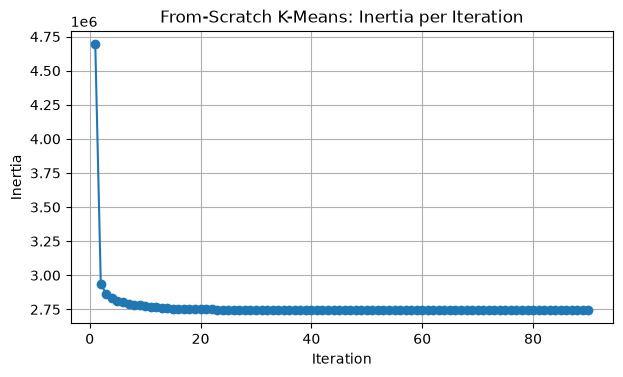


Images per cluster (from scratch):   [5309, 9968, 6778, 5384, 8606, 6700, 6453, 5265, 10434, 5103]
Images per cluster (scikit-learn):   [7688, 9121, 6415, 6090, 6419, 8328, 5473, 8307, 5867, 6292]


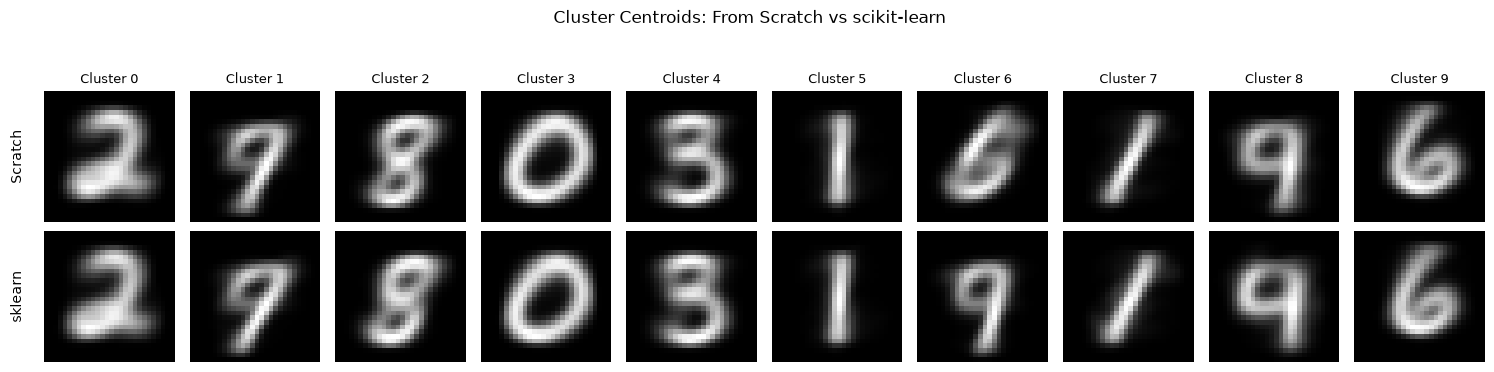

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist


# Scale pixels to 0-1 (explained in Section 4)

X_scaled = X_all / 255.0


# K-Means++ from scratch (NumPy)

class KMeansScratch:
    def __init__(self, n_clusters=10, n_init=3, max_iter=100, random_state=None):
        self.n_clusters = n_clusters
        self.n_init = n_init
        self.max_iter = max_iter
        self.random_state = random_state

    @staticmethod
    def _sq_dist(X, X_sq, C):
        # ||x - c||^2 = ||x||^2 - 2 x.c + ||c||^2  (one matrix multiplication)
        d2 = X_sq[:, None] - 2 * (X @ C.T) + (C ** 2).sum(axis=1)[None, :]
        return np.maximum(d2, 0)                                    # remove tiny negative rounding errors

    def _init_kmeanspp(self, X, X_sq, rng):
        n = len(X)
        centroids = [X[rng.integers(n)]]                            # first centroid: uniformly at random
        d2 = self._sq_dist(X, X_sq, centroids[0][None, :]).ravel()  # distance to the nearest chosen centroid
        for _ in range(1, self.n_clusters):
            probs = d2 / d2.sum()                                   # probability proportional to squared distance
            new = X[rng.choice(n, p=probs)]
            centroids.append(new)
            d2 = np.minimum(d2, self._sq_dist(X, X_sq, new[None, :]).ravel())
        return np.array(centroids)

    def _single_run(self, X, X_sq, rng):
        centroids = self._init_kmeanspp(X, X_sq, rng)
        labels = None
        inertia_history = []
        for it in range(self.max_iter):
            d2 = self._sq_dist(X, X_sq, centroids)
            new_labels = d2.argmin(axis=1)                          # assign step
            inertia_history.append(d2[np.arange(len(X)), new_labels].sum())
            if labels is not None and np.array_equal(new_labels, labels):
                break                                               # assignments stopped changing
            labels = new_labels
            for k in range(self.n_clusters):                        # update step
                members = X[labels == k]
                if len(members) > 0:
                    centroids[k] = members.mean(axis=0)
        # Exact final inertia, computed directly in float64
        inertia = float(((X - centroids[labels]) ** 2).sum(dtype=np.float64))
        return centroids, labels, inertia, inertia_history, it + 1

    def fit(self, X):
        rng = np.random.default_rng(self.random_state)
        X_sq = (X ** 2).sum(axis=1)
        best = None
        for _ in range(self.n_init):                                # keep the run with the lowest inertia
            run = self._single_run(X, X_sq, rng)
            if best is None or run[2] < best[2]:
                best = run
        (self.cluster_centers_, self.labels_, self.inertia_,
         self.inertia_history_, self.n_iter_) = best
        return self


# Fit from scratch

start = time.time()
km_scratch = KMeansScratch(n_clusters=10, n_init=3, random_state=42).fit(X_scaled)
time_scratch = time.time() - start
print(f"From scratch -> fit time {time_scratch:.1f} s | inertia {km_scratch.inertia_:,.1f} | iterations (best run) {km_scratch.n_iter_}")


# Fit scikit-learn (this model is reused in Sections 6 to 9)

start = time.time()
kmeans = KMeans(n_clusters=10, init="k-means++", n_init=3, random_state=42).fit(X_scaled)
fit_time = time.time() - start
cluster_labels = kmeans.labels_
print(f"scikit-learn -> fit time {fit_time:.1f} s | inertia {kmeans.inertia_:,.1f} | iterations (best run) {kmeans.n_iter_}")


# Comparison table

import pandas as pd

comparison_km = pd.DataFrame({
    "Inertia": [km_scratch.inertia_, kmeans.inertia_],
    "Iterations (best run)": [km_scratch.n_iter_, kmeans.n_iter_],
    "Fit time (s)": [time_scratch, fit_time],
}, index=["From scratch", "scikit-learn"])
display(comparison_km.round(2))

gap = abs(km_scratch.inertia_ - kmeans.inertia_) / kmeans.inertia_ * 100
print(f"\nInertia difference: {gap:.3f}%")
print(f"ARI between the two clusterings: {adjusted_rand_score(km_scratch.labels_, cluster_labels):.4f} (1 = identical groups)")


# Convergence of the from-scratch model (inertia per iteration, best run)

plt.figure(figsize=(7, 3.8))
plt.plot(range(1, len(km_scratch.inertia_history_) + 1), km_scratch.inertia_history_, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Inertia")
plt.title("From-Scratch K-Means: Inertia per Iteration")
plt.grid(True)
plt.show()


# Cluster sizes

print("\nImages per cluster (from scratch):  ", np.bincount(km_scratch.labels_, minlength=10).tolist())
print("Images per cluster (scikit-learn):  ", np.bincount(cluster_labels, minlength=10).tolist())


# Match each from-scratch centroid to its closest scikit-learn centroid (cluster IDs are arbitrary)

dist = cdist(km_scratch.cluster_centers_, kmeans.cluster_centers_)
rows, cols = linear_sum_assignment(dist)
order = cols[np.argsort(rows)]                                      # order[i] = sklearn cluster matching scratch cluster i


# Centroid images: from scratch (top) and scikit-learn (bottom, matched)

fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
for i in range(10):
    axes[0, i].imshow(km_scratch.cluster_centers_[i].reshape(28, 28), cmap="gray")
    axes[1, i].imshow(kmeans.cluster_centers_[order[i]].reshape(28, 28), cmap="gray")
    axes[0, i].set_title(f"Cluster {i}", fontsize=9)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].text(-0.15, 0.5, "Scratch", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.15, 0.5, "sklearn", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("Cluster Centroids: From Scratch vs scikit-learn", y=1.05)
plt.tight_layout()
plt.show()

### 4. Image Concepts and Choosing K

#### Image-specific concepts

| Concept | What it means | Why it matters here |
|:---|:---|:---|
| **Flattening** | A 28 × 28 image becomes a vector of 784 values | K-Means needs one feature vector per sample, so each pixel is a feature |
| **Normalization** | Pixel values are scaled from 0-255 to 0-1 | Keeps distances and inertia on a small, readable scale |
| **Curse of dimensionality** | In high dimensions, the nearest and farthest points end up at almost the same distance | "Nearest centroid" becomes less informative in 784 dimensions |

- Pixel distance compares images **pixel by pixel**, so the same digit written slightly shifted can be far apart. This is the main reason K-Means on raw pixels is limited.
- **Labels are not used** in any preprocessing step.

#### PCA, t-SNE and autoencoders

| | **PCA** | **t-SNE** | **Autoencoder** |
|:---|:---|:---|:---|
| **Type** | Linear projection | Non-linear embedding | Neural network (non-linear, learned) |
| **Idea** | Keeps the directions of greatest variance | Keeps nearby points nearby in a low-dimensional layout | Encoder compresses, decoder reconstructs; trained to minimize reconstruction error |
| **Main use** | Preprocessing before clustering | **Visualization only** | Learned features for clustering |
| **Transforms new data** | Yes | No | Yes |
| **Distances in output** | Meaningful | Cluster sizes and gaps are not reliable | Depends on training |

- **PCA** is used before K-Means, and **t-SNE** is used only to draw the clusters.
- **Autoencoders** are the non-linear counterpart of PCA. They are not part of the syllabus and are not implemented here.

#### Choosing K

| Method | Idea | Better when |
|:---|:---|:---|
| **Elbow method** | Plot inertia against K and look for the bend | Gains flatten out |
| **Silhouette score** | Compares distance to own cluster with distance to the nearest other cluster | Higher |
| **Calinski-Harabasz** | Between-cluster vs within-cluster dispersion | Higher |
| **Davies-Bouldin** | Average similarity of each cluster to its closest one | Lower |
| **Gap statistic** | Compares inertia with that of random reference data | Larger gap |
| **BIC / AIC** | Likelihood scores with a complexity penalty, for Gaussian mixtures | Lower |
| **Stability** | Re-cluster resampled data and check the groups agree | More stable |
| **Domain knowledge** | Use what is known about the problem | For MNIST, K = 10 (ten digits) |

- Inertia always falls as K grows, so it cannot pick K alone, and these measures often disagree.
- **K = 10 is used here** because MNIST has ten digits. Whether the clusters match the digits is checked in the evaluation section.

### 5. Evaluating Clusters Against True Labels

- Cluster IDs are arbitrary, so clusters are matched to digits before computing accuracy. **Labels are used for evaluation only.**

| Metric | Meaning |
|:---|:---|
| **Majority-vote accuracy (= purity)** | Each cluster is labeled with its most common digit; several clusters may share a digit |
| **Hungarian accuracy** | Best one-to-one matching of clusters to digits; the stricter, usual "clustering accuracy" |
| **ARI** | Pair-counting agreement corrected for chance (0 = random, 1 = perfect) |
| **NMI** | Shared information between clusters and labels (0 to 1) |

Majority-vote accuracy (purity): 0.5807
Hungarian accuracy:              0.5423
ARI:                             0.3659
NMI:                             0.4853

Majority-vote mapping (cluster -> digit): {0: np.int64(7), 1: np.int64(3), 2: np.int64(1), 3: np.int64(1), 4: np.int64(6), 5: np.int64(8), 6: np.int64(2), 7: np.int64(9), 8: np.int64(0), 9: np.int64(4)}
Hungarian mapping (cluster -> digit):    {0: np.int64(7), 1: np.int64(3), 2: np.int64(1), 3: np.int64(5), 4: np.int64(6), 5: np.int64(8), 6: np.int64(2), 7: np.int64(9), 8: np.int64(0), 9: np.int64(4)}
Digits with no cluster (majority vote): [5]


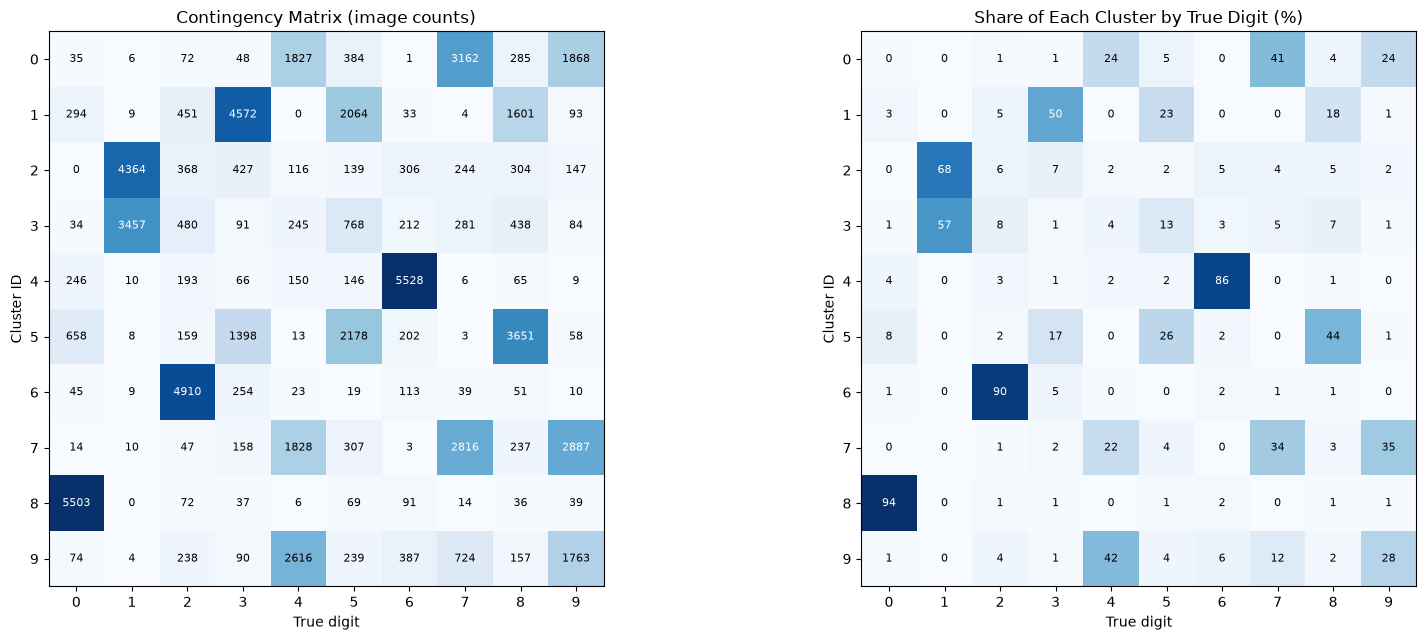

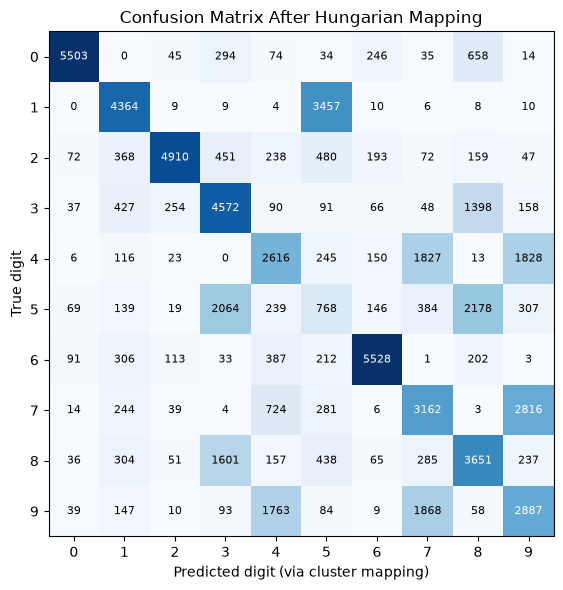

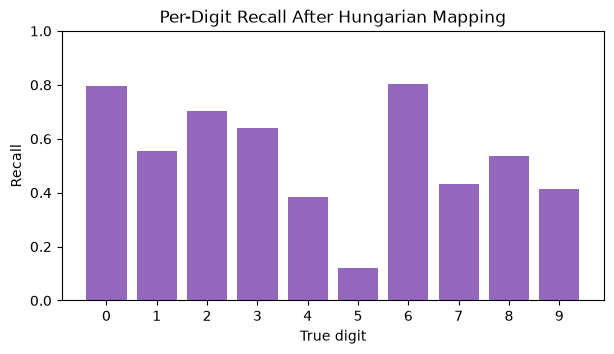

              precision    recall  f1-score   support

           0      0.938     0.797     0.862      6903
           1      0.680     0.554     0.611      7877
           2      0.897     0.702     0.788      6990
           3      0.501     0.640     0.562      7141
           4      0.416     0.383     0.399      6824
           5      0.126     0.122     0.124      6313
           6      0.861     0.804     0.832      6876
           7      0.411     0.434     0.422      7293
           8      0.438     0.535     0.482      6825
           9      0.348     0.415     0.378      6958

    accuracy                          0.542     70000
   macro avg      0.562     0.539     0.546     70000
weighted avg      0.566     0.542     0.550     70000

Most frequent confusions:
  digit 1 labeled as 5: 3,457 images (43.9% of all 1s)
  digit 7 labeled as 9: 2,816 images (38.6% of all 7s)
  digit 5 labeled as 8: 2,178 images (34.5% of all 5s)
  digit 5 labeled as 3: 2,064 images (32.7% of all

In [4]:
import pandas as pd
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (confusion_matrix, classification_report,
                             adjusted_rand_score, normalized_mutual_info_score)


# Contingency matrix: rows = clusters, columns = true digits

def contingency(y_true, clusters, n_clusters=10):
    cm = np.zeros((n_clusters, 10), dtype=int)
    np.add.at(cm, (clusters, y_true), 1)          # count images per (cluster, digit) pair
    return cm

cm = contingency(y_all, cluster_labels)
n = len(y_all)


# Majority-vote mapping and accuracy (this equals purity)

majority_map = cm.argmax(axis=1)                  # most common digit in each cluster
majority_acc = cm.max(axis=1).sum() / n


# Hungarian mapping: best one-to-one matching between clusters and digits

rows, cols = linear_sum_assignment(-cm)           # negative sign turns maximization into minimization
hungarian_map = np.zeros(10, dtype=int)
hungarian_map[rows] = cols
hungarian_acc = cm[rows, cols].sum() / n


# Label-independent scores

ari = adjusted_rand_score(y_all, cluster_labels)
nmi = normalized_mutual_info_score(y_all, cluster_labels)

print(f"Majority-vote accuracy (purity): {majority_acc:.4f}")
print(f"Hungarian accuracy:              {hungarian_acc:.4f}")
print(f"ARI:                             {ari:.4f}")
print(f"NMI:                             {nmi:.4f}")
print("\nMajority-vote mapping (cluster -> digit):", dict(enumerate(majority_map)))
print("Hungarian mapping (cluster -> digit):   ", dict(enumerate(hungarian_map)))
print("Digits with no cluster (majority vote):", sorted(set(range(10)) - set(majority_map)))


# Heatmaps: image counts (left) and row-normalized percentages (right)

cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, data, fmt, title in [(axes[0], cm, "{:d}", "Contingency Matrix (image counts)"),
                             (axes[1], cm_pct, "{:.0f}", "Share of Each Cluster by True Digit (%)")]:
    ax.imshow(data, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel("True digit"); ax.set_ylabel("Cluster ID")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, fmt.format(data[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if data[i, j] > data.max() / 2 else "black")
plt.tight_layout()
plt.show()


# Confusion matrix after Hungarian mapping (clusters treated as digit predictions)

y_pred_mapped = hungarian_map[cluster_labels]
cm_digits = confusion_matrix(y_all, y_pred_mapped)

plt.figure(figsize=(7, 6))
plt.imshow(cm_digits, cmap="Blues")
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel("Predicted digit (via cluster mapping)")
plt.ylabel("True digit")
plt.title("Confusion Matrix After Hungarian Mapping")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm_digits[i, j], ha="center", va="center", fontsize=8,
                 color="white" if cm_digits[i, j] > cm_digits.max() / 2 else "black")
plt.tight_layout()
plt.show()


# Per-digit recall

recall_per_digit = cm_digits.diagonal() / cm_digits.sum(axis=1)
plt.figure(figsize=(7, 3.5))
plt.bar(range(10), recall_per_digit, color="tab:purple")
plt.xticks(range(10)); plt.ylim(0, 1)
plt.xlabel("True digit"); plt.ylabel("Recall")
plt.title("Per-Digit Recall After Hungarian Mapping")
plt.show()

print(classification_report(y_all, y_pred_mapped, digits=3))


# Most frequent confusions (true digit grouped into another digit's cluster)

off_diag = cm_digits.copy()
np.fill_diagonal(off_diag, 0)                     # ignore correct assignments
top = np.dstack(np.unravel_index(np.argsort(off_diag.ravel())[::-1][:6], off_diag.shape))[0]
print("Most frequent confusions:")
for true_d, pred_d in top:
    share = off_diag[true_d, pred_d] / cm_digits[true_d].sum() * 100
    print(f"  digit {true_d} labeled as {pred_d}: {off_diag[true_d, pred_d]:,} images ({share:.1f}% of all {true_d}s)")

### 6. Cluster Visualization and Interpretation

- **Centroid images:** each centroid is the average image of its cluster. A clear digit means a clean cluster; a blur means mixed digits.
- **Cluster table and samples:** show what each cluster actually contains.
- **PCA 2-D and t-SNE 2-D:** drawn twice, colored by K-Means cluster and by true digit, on a 5,000-image sample. t-SNE cluster sizes and gaps are not reliable, and it is used for display only.

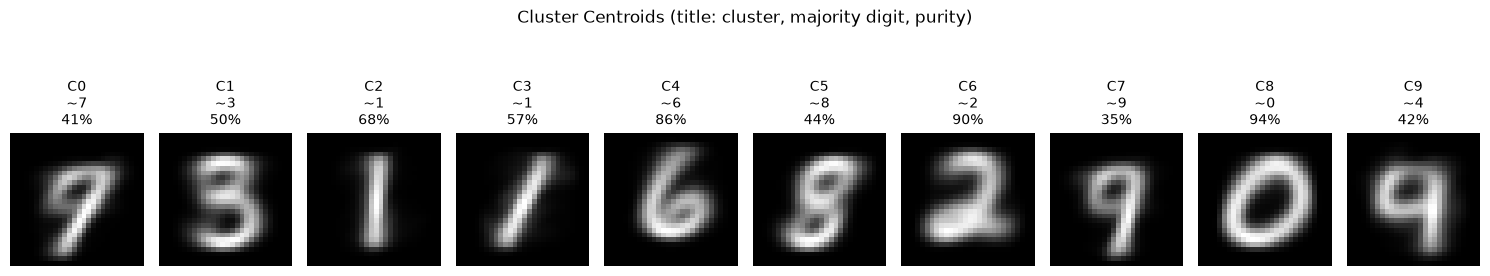

,Cluster,Size,Majority digit,Purity (%),Runner-up digit,Runner-up share (%)
0,0,7688,7,41.1,9,24.3
1,1,9121,3,50.1,5,22.6
2,2,6415,1,68.0,3,6.7
3,3,6090,1,56.8,5,12.6
4,4,6419,6,86.1,0,3.8
5,5,8328,8,43.8,5,26.2
6,6,5473,2,89.7,3,4.6
7,7,8307,9,34.8,7,33.9
8,8,5867,0,93.8,6,1.6
9,9,6292,4,41.6,9,28.0


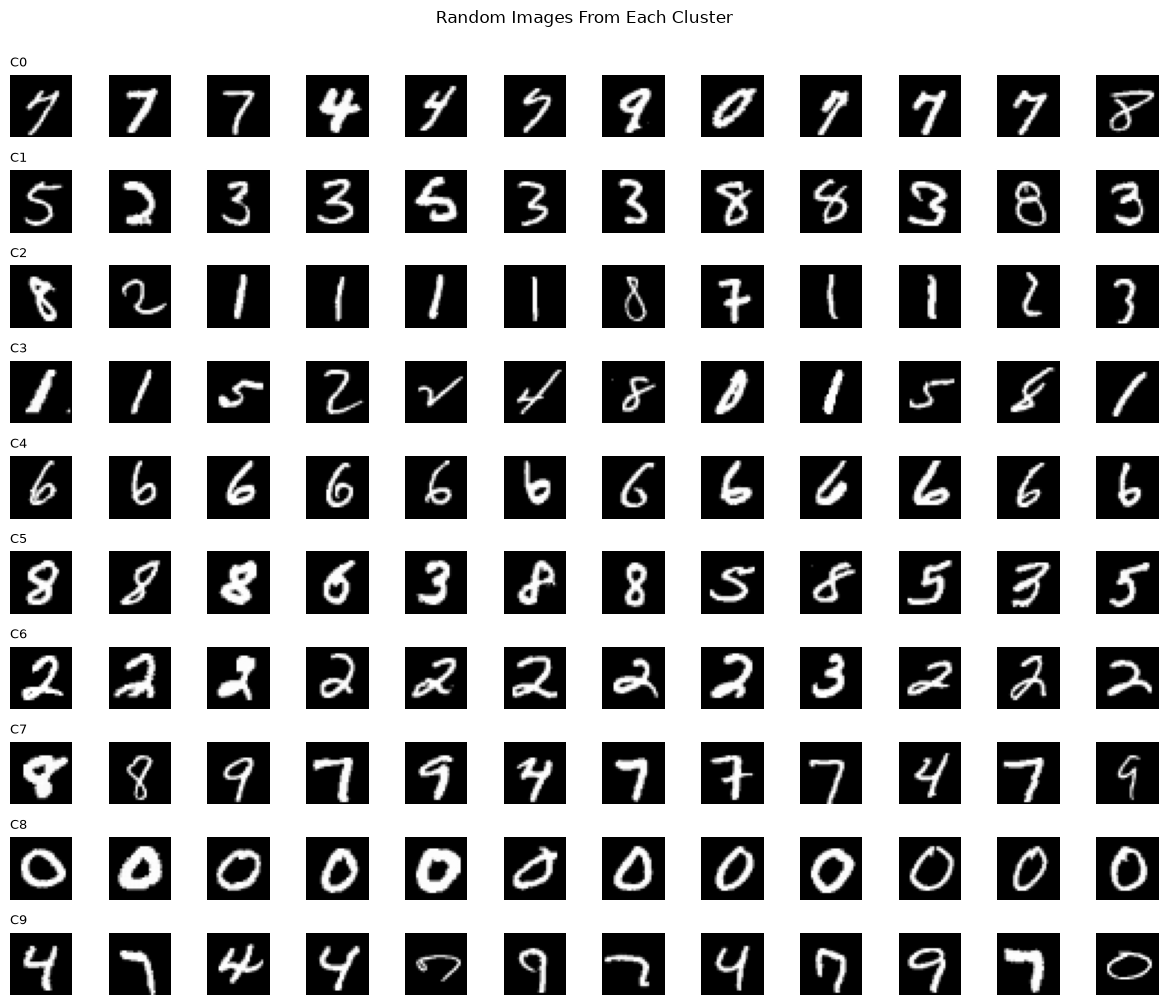

Variance kept by the first 2 components: 16.9%


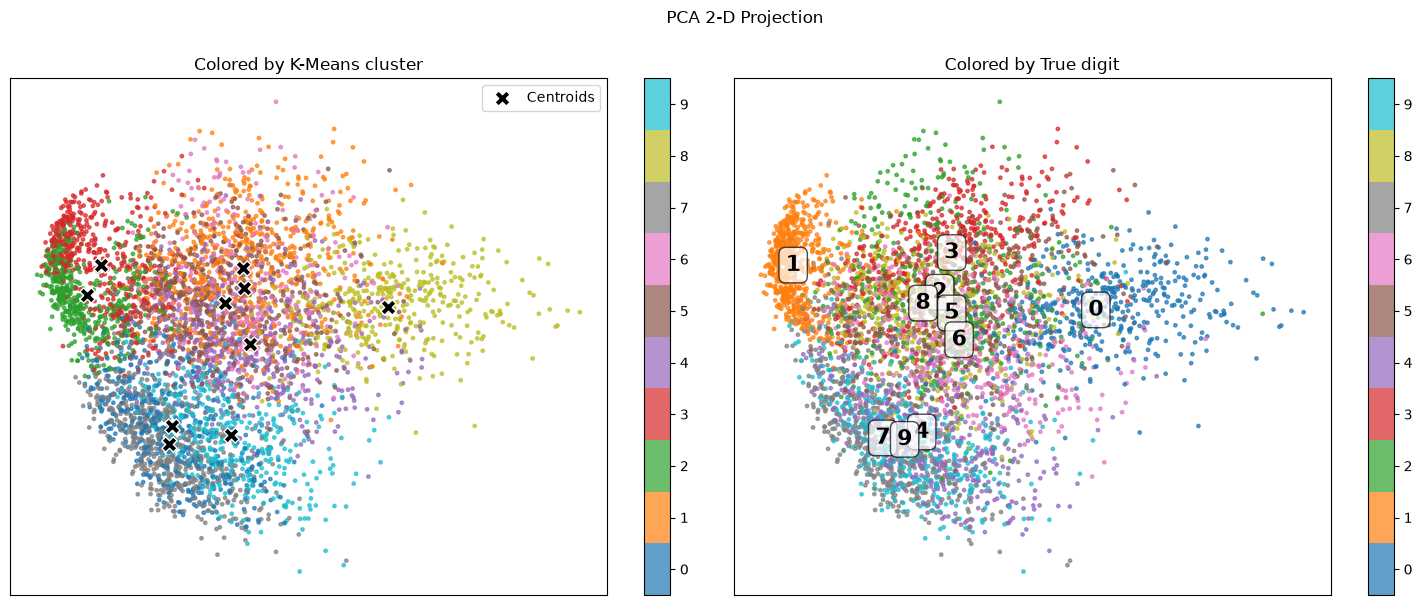

t-SNE time: 53.9 s


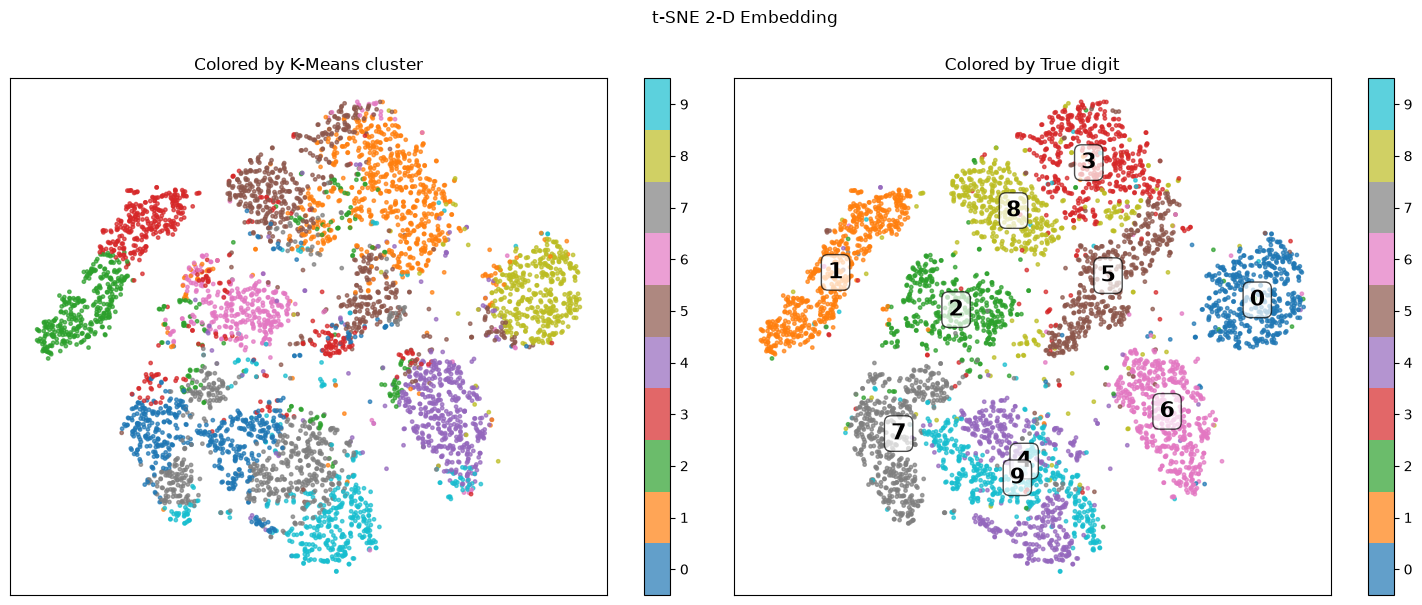

In [5]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


# Centroid images, titled with cluster, majority digit and purity

purity_per_cluster = cm.max(axis=1) / cm.sum(axis=1)

fig, axes = plt.subplots(1, 10, figsize=(15, 2.8))
for k in range(10):
    axes[k].imshow(kmeans.cluster_centers_[k].reshape(28, 28), cmap="gray")
    axes[k].set_title(f"C{k}\n~{majority_map[k]}\n{purity_per_cluster[k] * 100:.0f}%", fontsize=10)
    axes[k].axis("off")
plt.suptitle("Cluster Centroids (title: cluster, majority digit, purity)", y=1.12)
plt.tight_layout()
plt.show()


# Cluster summary table: size, majority digit, purity and runner-up digit

summary_rows = []
for k in range(10):
    order = np.argsort(cm[k])[::-1]               # digits sorted by frequency within the cluster
    summary_rows.append({
        "Cluster": k,
        "Size": cm[k].sum(),
        "Majority digit": order[0],
        "Purity (%)": round(cm[k, order[0]] / cm[k].sum() * 100, 1),
        "Runner-up digit": order[1],
        "Runner-up share (%)": round(cm[k, order[1]] / cm[k].sum() * 100, 1),
    })
display(pd.DataFrame(summary_rows))


# Random images from each cluster (each row = one cluster)

rng = np.random.default_rng(42)
n_show = 12
fig, axes = plt.subplots(10, n_show, figsize=(n_show, 10))
for k in range(10):
    members = np.where(cluster_labels == k)[0]
    chosen = rng.choice(members, n_show, replace=False)
    for j, i in enumerate(chosen):
        axes[k, j].imshow(X_scaled[i].reshape(28, 28), cmap="gray")
        axes[k, j].axis("off")
        if j == 0:
            axes[k, j].set_title(f"C{k}", fontsize=9, loc="left")
plt.suptitle("Random Images From Each Cluster", y=1.0)
plt.tight_layout()
plt.show()


# Sample of 5,000 images for the 2-D projections

idx_vis = rng.choice(len(X_scaled), 5000, replace=False)
X_vis, y_vis, c_vis = X_scaled[idx_vis], y_all[idx_vis], cluster_labels[idx_vis]


# Helper: one embedding colored by cluster (left) and by true digit (right)

def plot_embedding(Z, title, centroids_2d=None):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, colors, name in [(axes[0], c_vis, "K-Means cluster"), (axes[1], y_vis, "True digit")]:
        sc = ax.scatter(Z[:, 0], Z[:, 1], c=colors, cmap="tab10", vmin=-0.5, vmax=9.5, s=6, alpha=0.7)
        ax.set_title(f"Colored by {name}")
        ax.set_xticks([]); ax.set_yticks([])
        plt.colorbar(sc, ax=ax, ticks=range(10))
    if centroids_2d is not None:                  # mark the projected centroids
        axes[0].scatter(centroids_2d[:, 0], centroids_2d[:, 1], c="black", marker="X", s=120,
                        edgecolors="white", label="Centroids")
        axes[0].legend()
    for d in range(10):                           # label each true digit at its median position
        mx, my = np.median(Z[y_vis == d], axis=0)
        axes[1].text(mx, my, str(d), fontsize=16, weight="bold", ha="center", va="center",
                     bbox=dict(boxstyle="round", fc="white", alpha=0.7))
    plt.suptitle(title, y=1.0)
    plt.tight_layout()
    plt.show()


# PCA 2-D projection (fitted on all images), with centroids projected too

pca2 = PCA(n_components=2, random_state=42).fit(X_scaled)
print(f"Variance kept by the first 2 components: {pca2.explained_variance_ratio_.sum() * 100:.1f}%")
plot_embedding(pca2.transform(X_vis), "PCA 2-D Projection", pca2.transform(kmeans.cluster_centers_))


# t-SNE 2-D embedding (PCA to 50 dimensions first for speed and noise reduction)

start = time.time()
X_vis_50 = PCA(n_components=50, random_state=42).fit_transform(X_vis)
Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(X_vis_50)
print(f"t-SNE time: {time.time() - start:.1f} s")
plot_embedding(Z_tsne, "t-SNE 2-D Embedding")

### 7. Conclusion

#### Results

| Implementation | Inertia | Iterations | Fit time (s) |
|:---|:---:|:---:|:---:|
| **From scratch** | 2,744,060 | 90 | 69.4 |
| **scikit-learn** | 2,744,538 | 69 | 127.1 |

Inertia differs by only **0.017%**, and the ARI between the two clusterings is **0.653**.

| Metric | Score |
|:---|:---:|
| Majority-vote accuracy (purity) | 0.581 |
| Hungarian accuracy | 0.542 |
| ARI | 0.366 |
| NMI | 0.485 |

#### Observations

- **Implementations agree:** the from-scratch model reaches almost the same inertia as scikit-learn. The moderate ARI (0.653) is expected, since different K-Means++ starts (`n_init=3`) land in different local minima of similar quality.
- **Unsupervised vs supervised:** about 54 to 58% accuracy is far above random guessing (10%), but well below supervised classifiers on MNIST (over 97%). Compact clusters in pixel space are not the same as digit categories.
- **Clean clusters:** digits 0 (93.8% purity), 2 (89.7%) and 6 (86.1%) formed the clearest clusters, and their centroids show crisp strokes.
- **Mixed clusters:** digit 5 was not the majority in any cluster (recall 0.122), and digit 1 was split across two clusters (upright vs slanted). Mixed clusters have blurry centroids.
- **Main confusions:** 7 with 9 (38.6% of 7s), 5 with 8 and 3 (34.5% and 32.7%), 9 with 7 (26.8%) and 4 with 9 (26.8%). The 1 to 5 confusion (43.9% of 1s) is a side effect of the one-to-one mapping, caused by 1 being split.
- **Plots:** the 2-D PCA keeps only 16.9% of the variance, so clusters overlap heavily. t-SNE shows clearer local structure, but groups such as 3/5/8 and 4/7/9 stay entangled.
- **Why raw pixels struggle:** Euclidean distance treats every pixel equally, so a small shift or thickness change makes two identical digits look far apart, while different digits with overlapping shapes look close.

#### Limitations and next steps

- **K fixed at 10:** this forces style variants (such as slanted 1s) to compete with real digit classes. Testing K between 10 and 20 could help.
- **No dimensionality reduction:** PCA before clustering, or autoencoder features, may give more meaningful groups.
- **Local minima:** with `n_init=3` and one seed, results are not fully stable. More restarts would help.
- **Cluster shape assumption:** K-Means expects round, similar-sized clusters. Gaussian mixtures or density-based methods (such as UMAP with HDBSCAN) may fit digit shapes better.